# Clasificación de Datos

### Importar librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

### Carga de datos

In [2]:
df_biare = pd.read_csv("../Limpieza de datos (Practica 1)/biare_limpio_2021_2024.csv")

### Agrupamos nuestros valores para poder dividir en tres niveles de satisfacción con la vida

Agrupamos nuestras respuestas para dividir en nivel de satisfacción con la vida en baja (0-6), media (7-8) y alta (9-10)

In [3]:
#creamos una nueva columna con la satisfacción con la vida y dividimos en categorias de satisfaccion de vida en baja (0-6), media (7-8) y alta (9-10)
df_biare['satisfaccion_vida'] = pd.cut(df_biare['cb_P1'], bins=[-1, 6, 8, 10], labels=['Baja', 'Media', 'Alta'])

#vemos la distribucion de nuestra categoria
print(df_biare['satisfaccion_vida'].value_counts())
print(df_biare['satisfaccion_vida'].value_counts(normalize=True).round(3))

satisfaccion_vida
Alta     4073
Media    3147
Baja      799
Name: count, dtype: int64
satisfaccion_vida
Alta     0.508
Media    0.392
Baja     0.100
Name: proportion, dtype: float64


### Separamos nuestras demás variables de nuestra variable objetivo

In [4]:
#una lista con nuestras variables que nos ayudaran a predecir el nivel de satisfaccion con la vida
predictores = ['cb_P3_1', 'cb_P5_1', 'cb_P3_2', 'cb_P3_5', 'cb_P5_2',
               'cb_P3_6', 'cb_P5_3', 'cb_P5_5', 'cb_P3_10', 'cb_P5_4']
#creamos un dataframe con las variables predictoras y la variable objetivo quitando nulos
datos = df_biare[predictores + ['satisfaccion_vida']].dropna()

#separamos las variables que predicen y la variable objetivo
x = datos[predictores]
y = datos['satisfaccion_vida']


### Separamos los datos de entrenamiento de los de prueba

separamos los datos de entrenamiento de los de prueba, el 80% delos datos serviran para entrenar mientras que el 20% serán para predecir, el random state asegura que los resultados sean los mismo minetras que stratify se asegura que se tenga el mismo porcentaje de nivel de educacion

In [5]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)


### Escalamos los datos para que su distancia sea normalizada

se escalan los datos para que las distancias que se miden tengan la misma escala, es una normalizacion que nos indica a cuantas desviaciones estandar se encuentran los vecinos mas cercanos

In [6]:
#usamos standarscaler para ver que tan lejos o que tan cerca esta del promedio
escala = StandardScaler()

#escalamos los datos de entrenamiento y prueba
X_train_esc = escala.fit_transform(X_train)
X_test_esc = escala.transform(X_test)

print(y_test.value_counts())

satisfaccion_vida
Alta     815
Media    629
Baja     160
Name: count, dtype: int64


debido a que tenemos pocos bajos, es probable que no tengamos mucha exactitud con esta categoria

### Hacemos pruebas con k para saber cuantos vecinos visitar

k representa el número de vecinos que nuestro knn debe consultar para asignarle una categoría

In [7]:
#la lista con el nuumero de vecinos que debe visitar, del 1 a 52, va de uno en uno para el for
valores_k = range(1, 52, 1)
#resultados
exactitudes_cv = []

#for para ver el resultado de cada numero
for k in valores_k:
    #se hace el modelo knn que visitara los k valores que tenemos en la lista, el entrenamiento se divide en 5 partes
    #una parte se usa para prueba y las otras 4 para entrenamiento y al final se le da un score.
    puntajes = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_esc, y_train, cv=5)
    #se promedian los valores de las 5 partes y se obtiene un valor final
    exactitudes_cv.append(puntajes.mean())

#vemos cual es el valor de k que nos da el mejor resultado
mejor_k = list(valores_k)[int(np.argmax(exactitudes_cv))]
print(f"k que mas nos sirve: {mejor_k}")

k que mas nos sirve: 30


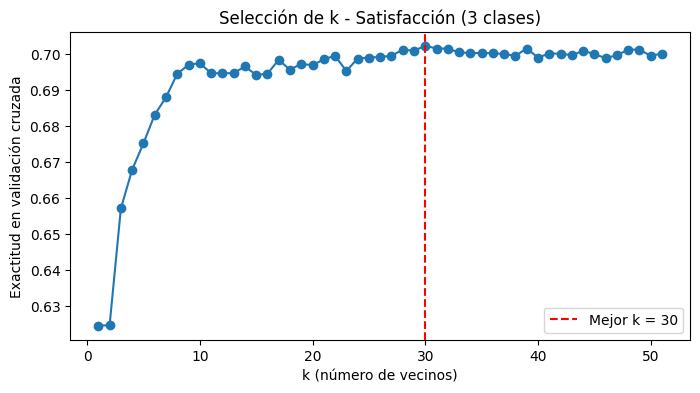

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(list(valores_k), exactitudes_cv, marker='o')
plt.axvline(mejor_k, color='red', linestyle='--', label=f'Mejor k = {mejor_k}')
plt.xlabel('k (número de vecinos)')
plt.ylabel('Exactitud en validación cruzada')
plt.title('Selección de k - Satisfacción (3 clases)')
plt.legend()
plt.show()

### Matriz de confusion

In [10]:
#creamos el modelo con la mejor k y lo entrenamos con los datos de entrenamiento
knn_vida = KNeighborsClassifier(n_neighbors=mejor_k)
knn_vida.fit(X_train_esc, y_train)

#predecimos usando el conjunto de prueba
y_pred_vida = knn_vida.predict(X_test_esc)
etiquetas = ['Baja', 'Media', 'Alta']
#se ve la exactitud que es la comparacion entre lo real y lo predicho
print(f"Exactitud: {accuracy_score(y_test, y_pred_vida):.3f}")
#la clase con mayor representacion en la prueba
print(f"clase más común: {y_test.value_counts(normalize=True).max():.3f}")
print()
print(classification_report(y_test, y_pred_vida, labels=etiquetas))

#creamos la matriz de confusion del modelo
cm = confusion_matrix(y_test, y_pred_vida, labels=etiquetas)

print(pd.DataFrame(cm, index=['Real: ' + e for e in etiquetas], columns=['Pred: ' + e for e in etiquetas]))

Exactitud: 0.685
clase más común: 0.508

              precision    recall  f1-score   support

        Baja       0.75      0.26      0.39       160
       Media       0.63      0.63      0.63       629
        Alta       0.72      0.81      0.76       815

    accuracy                           0.68      1604
   macro avg       0.70      0.57      0.59      1604
weighted avg       0.69      0.68      0.67      1604

             Pred: Baja  Pred: Media  Pred: Alta
Real: Baja           42           84          34
Real: Media          11          395         223
Real: Alta            3          151         661


De los resultados podemos ver que el modelo en total tiene una exactitud del 68%, algo que es muy malo y que nos indica que las variables que deben de predecir el nivel de satisfaccion con la vida no lo hacen correctamente.

Por su parte hablando de cada clase en especifico hablando del nivel bajo, en precision, de todos los que nombro bajas (includos los que no eran pero igual nombro), el 75% eran baja, mientras que de los que tenia que nombrar bajas, acertó el 26%, esto es muy grave, ya que de cada 4 personas que debe detectar baja, solo dectecta 1, aunque es necesario recalcar que hay muy pocos bajos, por lo que es complicado poder predecirlo.

Hablando del nivel media en precision, de todos los que nombro media (includos los que no eran pero igual nombro), el 63% eran media, mientras que de los que tenia que nombrar media, acertó tambien el 63%.

Hablando del nivel alto, en precision, de todos los que nombro alta (includos los que no eran pero igual nombro), el 72% eran altos, mientras que de los que tenia que nombrar superior, acertó el 81%, el mejor de todos los que tenemos, hace sentido ya que son también de los que más datos tenemos.

Con esto vemos que nuestro modelo no funciona para predecir el nivel de satisfaccion con la vida de las personas, principalmente debido a la poca cantidad de valores bajos que tenemos.